In [1]:
import pandas as pd
import ast
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
from scipy.stats import mannwhitneyu

In [2]:
def is_missing(s):
    """True where a value is NaN, 0 (numeric columns) or an empty list/blank (text columns)."""
    if pd.api.types.is_numeric_dtype(s):
        return s.isna() | (s == 0)
    t = s.astype("string").str.strip()
    return s.isna() | t.isin(["", "[]", "0"])

def capped_labels(s, cap):
    s = s.dropna().astype(int)
    return s.where(s <= cap, cap).map(lambda v: f"{cap}+" if v == cap else str(v))

def plot_against(target, data):
    fig, axes = plt.subplots(2, 4, figsize=(18, 9), layout="constrained")
    axes = axes.ravel()
    ylim = (np.floor(data[target].min()), np.ceil(data[target].max()))
    norm = LogNorm(vmin=1, vmax=3000)            # same colour scale in every density panel

    for ax, (col, lim) in zip(axes[:4], CONTINUOUS.items()):
        d = data[[col, target]].dropna()
        if lim:
            d = d[d[col].between(*lim)]
        rho = d[col].corr(d[target], method="spearman")
        hb = ax.hexbin(d[col], d[target], gridsize=40, cmap="Blues", mincnt=1, norm=norm, linewidths=0.2)

        # Median line: 20 equal-width bins, skipping bins with < 30 games
        g = d.groupby(pd.cut(d[col], 20), observed=True)
        trend = g.agg(x=(col, "median"), y=(target, "median"), n=(target, "size")).query("n >= 30")
        ax.plot(trend.x, trend.y, color=RED, lw=2, marker="o", ms=4, label="median")

        ax.set_title(f"{col}   ρ = {rho:.2f}   (n={len(d):,})", fontsize=10)
        ax.set_xlabel(col)

    for ax, (col, cap) in zip(axes[4:7], DISCRETE.items()):
        lab = capped_labels(data[col], cap)
        order = [o for o in [str(i) for i in range(1, cap)] + [f"{cap}+"] if o in set(lab)]
        groups = [data.loc[lab.index[lab == o], target] for o in order]
        rho = data[col].corr(data[target], method="spearman")
        ax.boxplot(groups, tick_labels=order, showfliers=False, widths=0.6,
                   medianprops=dict(color=RED, lw=2), boxprops=dict(color=BLUE),
                   whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
        for i, gr in enumerate(groups, 1):
            ax.text(i, ylim[0] + 0.03 * (ylim[1] - ylim[0]), f"n={len(gr):,}",
                    ha="center", va="bottom", fontsize=7, color="#666", rotation=90)
        ax.set_title(f"{col}   ρ = {rho:.2f}   (n={lab.size:,})", fontsize=10)
        ax.set_xlabel(col)
        ax.grid(axis="y", alpha=0.3)

    for ax in axes[:7]:
        ax.set_ylim(*ylim)
        ax.set_ylabel(target)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(loc="lower right", frameon=False)

    axes[7].set_visible(False)
    fig.colorbar(hb, ax=axes[7], location="left", shrink=0.8, label="games per hexagon (log scale)")
    fig.suptitle(f"{target} compared with game metrics", fontsize=14)
    plt.show()

In [3]:
# Continuous metrics -> density plot (optional x-range)
# Player counts -> box plot, with the highest group shown as "cap+"
CONTINUOUS = {"GameWeight": None, "YearPublished": (1950, 2021), "ComAgeRec": None, "LanguageEase": None}
DISCRETE = {"MaxPlayers": 10, "BestPlayers": 8, "MinPlayers": 6}
BLUE, RED = "#2a6f97", "#d1495b"

In [4]:
games = pd.read_csv("Data/board-games-database-from-boardgamegeek/games.csv")
gdf = games.iloc[:, 1:14].copy() #columns 1:14 of the games-dataframe, aka the first 13 columns excluding the id
gdf.columns.tolist()

['Name',
 'Description',
 'YearPublished',
 'GameWeight',
 'AvgRating',
 'BayesAvgRating',
 'StdDev',
 'MinPlayers',
 'MaxPlayers',
 'ComAgeRec',
 'LanguageEase',
 'BestPlayers',
 'GoodPlayers']

In [5]:
gdf.head()

,Name,Description,YearPublished,GameWeight,AvgRating,BayesAvgRating,StdDev,MinPlayers,MaxPlayers,ComAgeRec,LanguageEase,BestPlayers,GoodPlayers
0,Die Macher,die macher game seven sequential political rac...,1986,4.3206,7.61428,7.10363,1.57979,3,5,14.366667,1.395833,5,"['4', '5']"
1,Dragonmaster,dragonmaster tricktaking card game base old ga...,1981,1.9630,6.64537,5.78447,1.45440,3,4,NaN,27.000000,0,[]
2,Samurai,samurai set medieval japan player compete gain...,1998,2.4859,7.45601,7.23994,1.18227,2,4,9.307692,1.000000,3,"['2', '3', '4']"
3,Tal der Könige,triangular box luxurious large block tal der k...,1992,2.6667,6.60006,5.67954,1.23129,2,4,13.000000,256.000000,0,[]
4,Acquire,acquire player strategically invest business t...,1964,2.5031,7.33861,7.14189,1.33583,2,6,11.410256,21.152941,4,"['3', '4', '5']"


In [6]:
missing = gdf.apply(is_missing)
gdf['GoodPlayers'].apply(ast.literal_eval)

overview = pd.DataFrame({
    "dtype": gdf.dtypes,
    "NaN": gdf.isna().sum(),
    "zero": gdf.select_dtypes("number").eq(0).sum().reindex(gdf.columns, fill_value=0),
    "empty_list": gdf.apply(lambda s: s.astype("string").str.strip().eq("[]").sum() if s.dtype == object else 0),
    "missing_total": missing.sum(),
    "missing_pct": (missing.mean() * 100).round(2),
    "unique_values": gdf.nunique(),
})
overview

,dtype,NaN,zero,empty_list,missing_total,missing_pct,unique_values
Name,str,0,0,0,0,0.00,21521
Description,str,1,0,0,1,0.00,21903
YearPublished,int64,0,193,0,193,0.88,188
GameWeight,float64,0,506,0,506,2.31,3921
AvgRating,float64,0,0,0,0,0.00,20489
BayesAvgRating,float64,0,0,0,0,0.00,15950
StdDev,float64,0,0,0,0,0.00,19527
MinPlayers,int64,0,50,0,50,0.23,11
MaxPlayers,int64,0,173,0,173,0.79,54
ComAgeRec,float64,5530,0,0,5530,25.22,1366


,count,mean,std,min,25%,50%,75%,max
YearPublished,21732.0,2003.13,101.14,-3500.00,2002.00,2011.00,2017.00,2021.00
GameWeight,21419.0,2.03,0.80,1.00,1.33,2.00,2.55,5.00
AvgRating,21925.0,6.42,0.93,1.04,5.84,6.45,7.05,9.91
BayesAvgRating,21925.0,5.69,0.37,3.57,5.51,5.55,5.68,8.51
StdDev,21925.0,1.52,0.29,0.20,1.32,1.48,1.67,4.28
MinPlayers,21875.0,2.01,0.69,1.00,2.00,2.00,2.00,10.00
MaxPlayers,21752.0,5.75,15.07,1.00,4.00,4.00,6.00,999.00
ComAgeRec,16395.0,10.00,3.27,2.00,8.00,10.00,12.00,21.00
LanguageEase,16034.0,216.46,236.60,1.00,24.03,138.00,351.00,1757.00
BestPlayers,1981.0,3.45,1.34,1.00,2.00,4.00,4.00,15.00


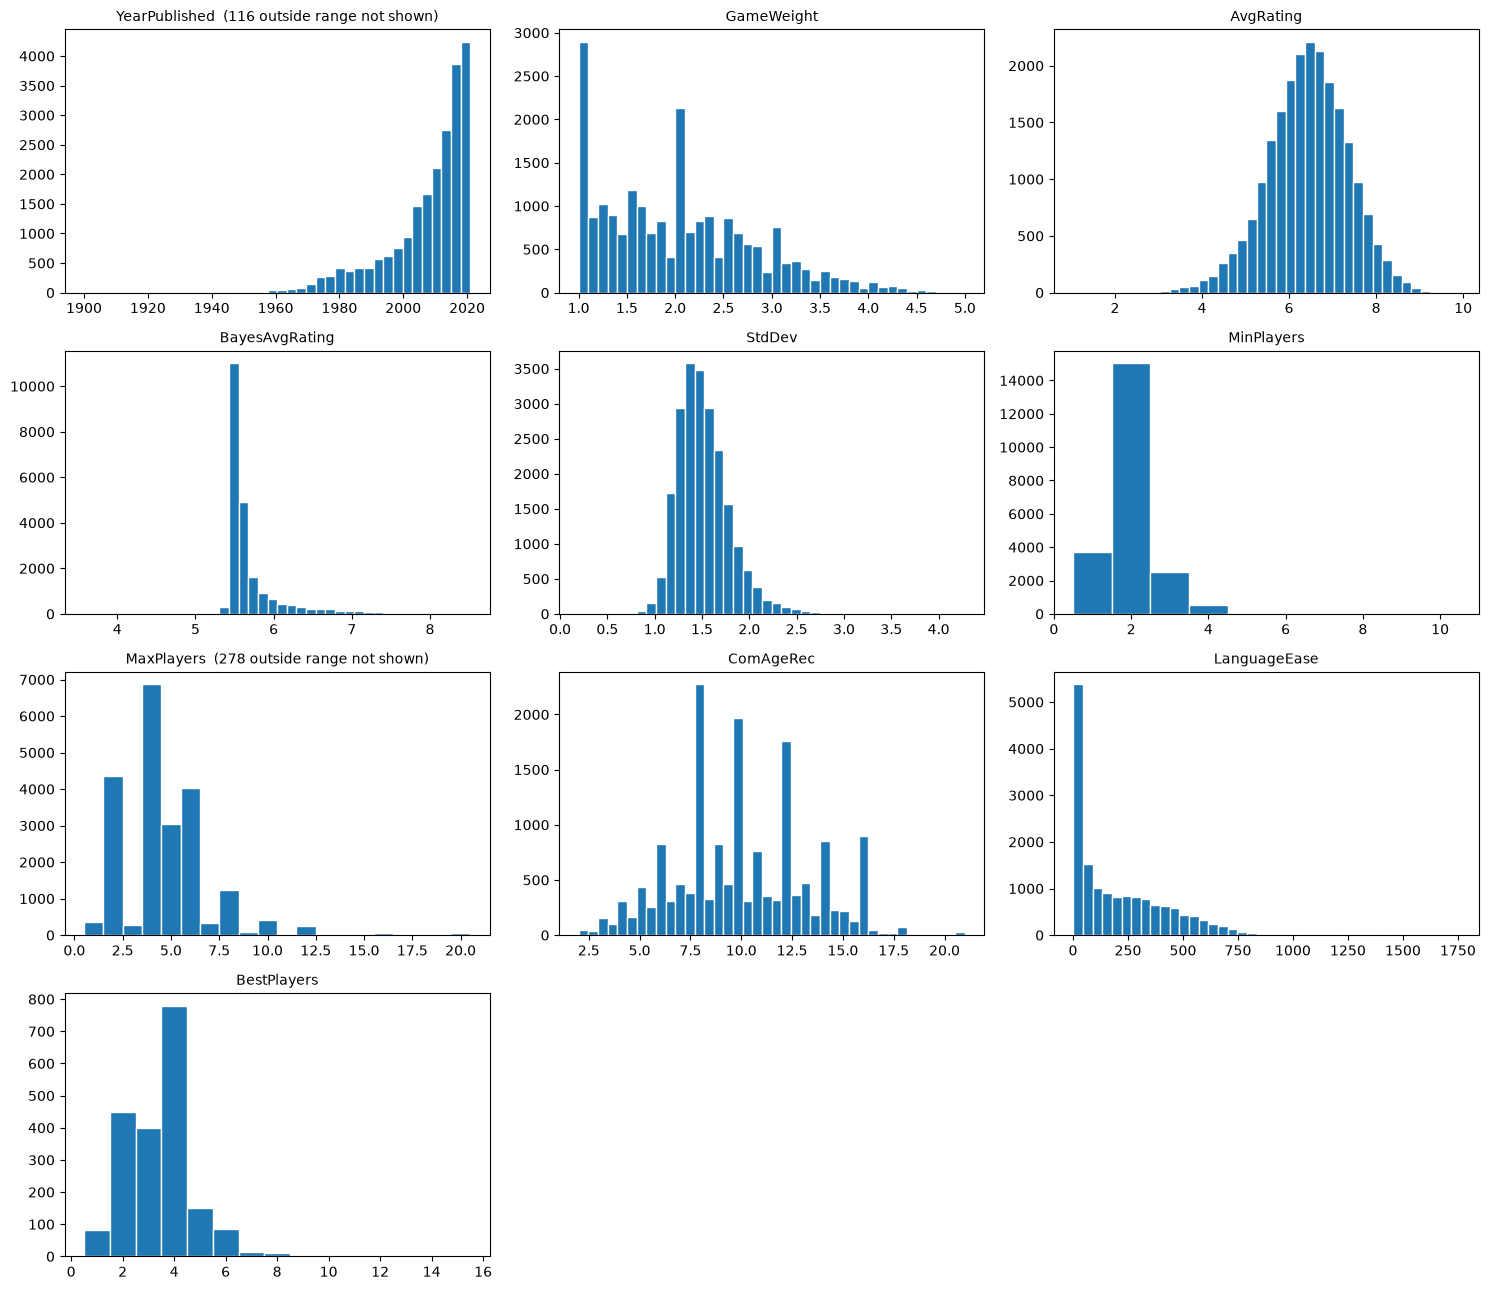

In [7]:
num = gdf.select_dtypes("number").mask(missing)   # zeros become NaN; gdf itself is unchanged
display(num.describe().T.round(2))

# Limit only what is plotted; the data keeps every value
plot_limits = {"YearPublished": (1900, None), "MaxPlayers": (None, 20)}

fig, axes = plt.subplots(4, 3, figsize=(15, 13))
axes = axes.ravel()

for ax, col in zip(axes, num.columns):
    s = num[col].dropna()
    lo, hi = plot_limits.get(col, (None, None))
    shown = s[(s >= (lo if lo is not None else -np.inf)) & (s <= (hi if hi is not None else np.inf))]

    # Whole-number columns get one bar per value; the rest get 40 bins
    if pd.api.types.is_integer_dtype(gdf[col]) and shown.nunique() <= 40:
        bins = np.arange(shown.min(), shown.max() + 2) - 0.5
    else:
        bins = 40

    ax.hist(shown, bins=bins, edgecolor="white")
    hidden = len(s) - len(shown)
    ax.set_title(col + (f"  ({hidden} outside range not shown)" if hidden else ""), fontsize=10)

for ax in axes[len(num.columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

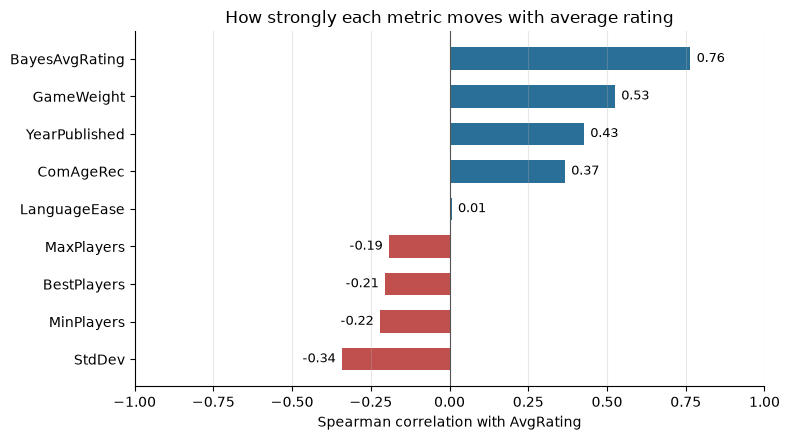

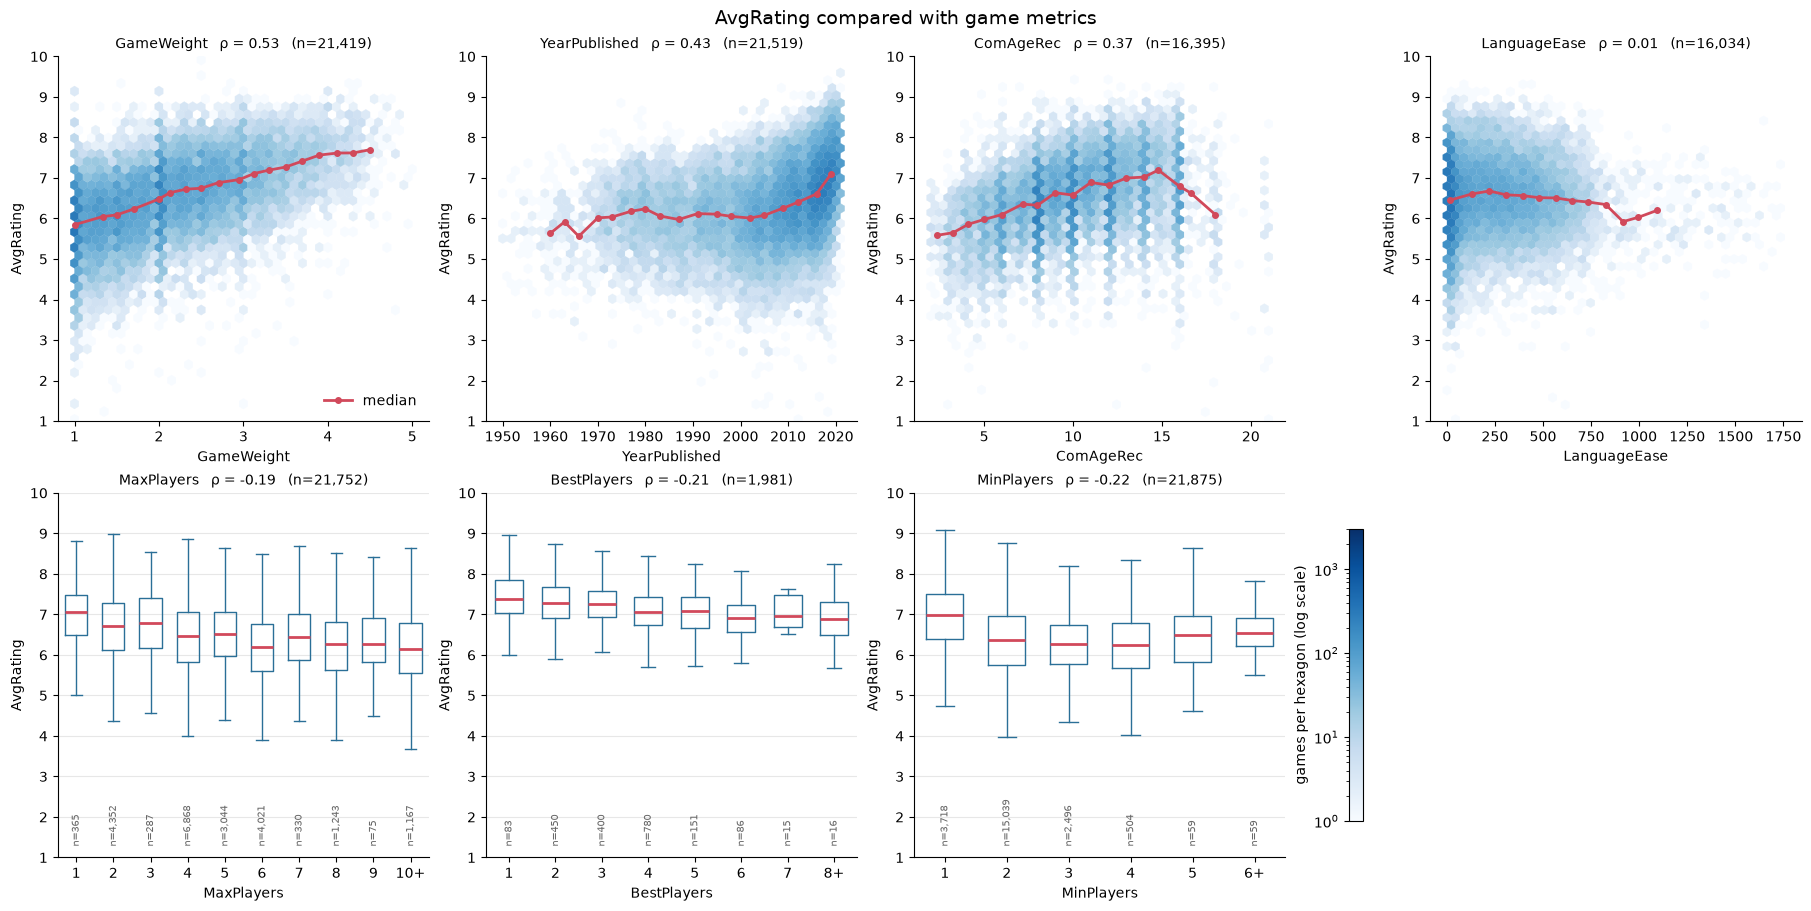

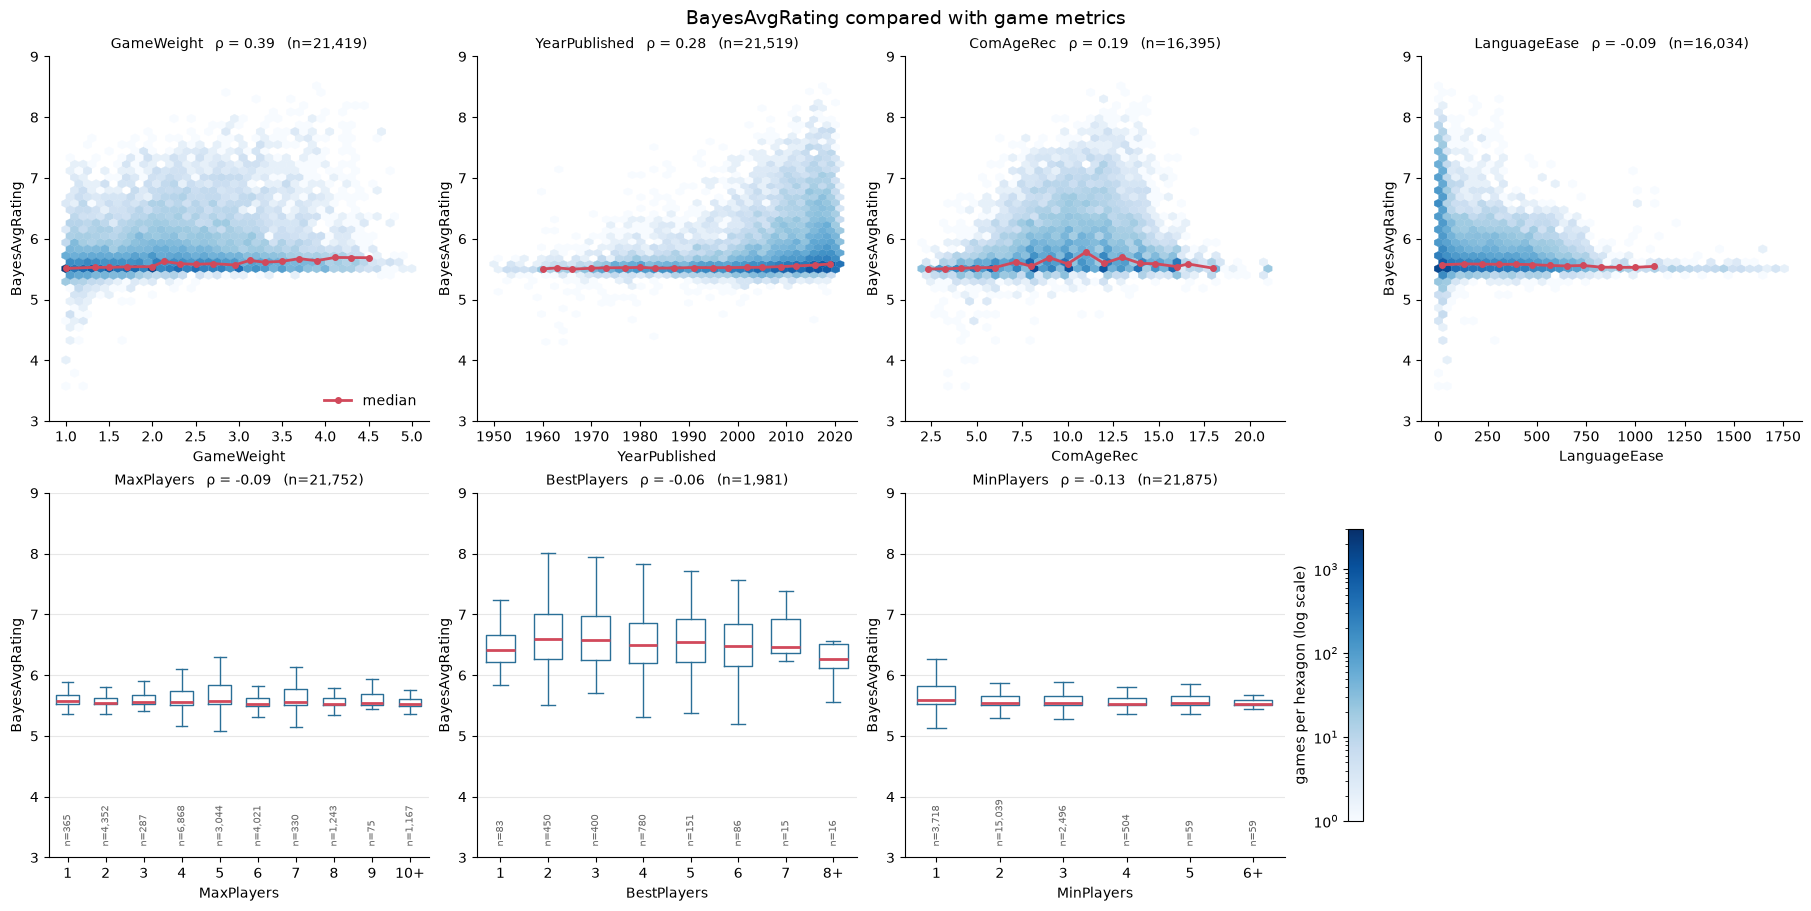

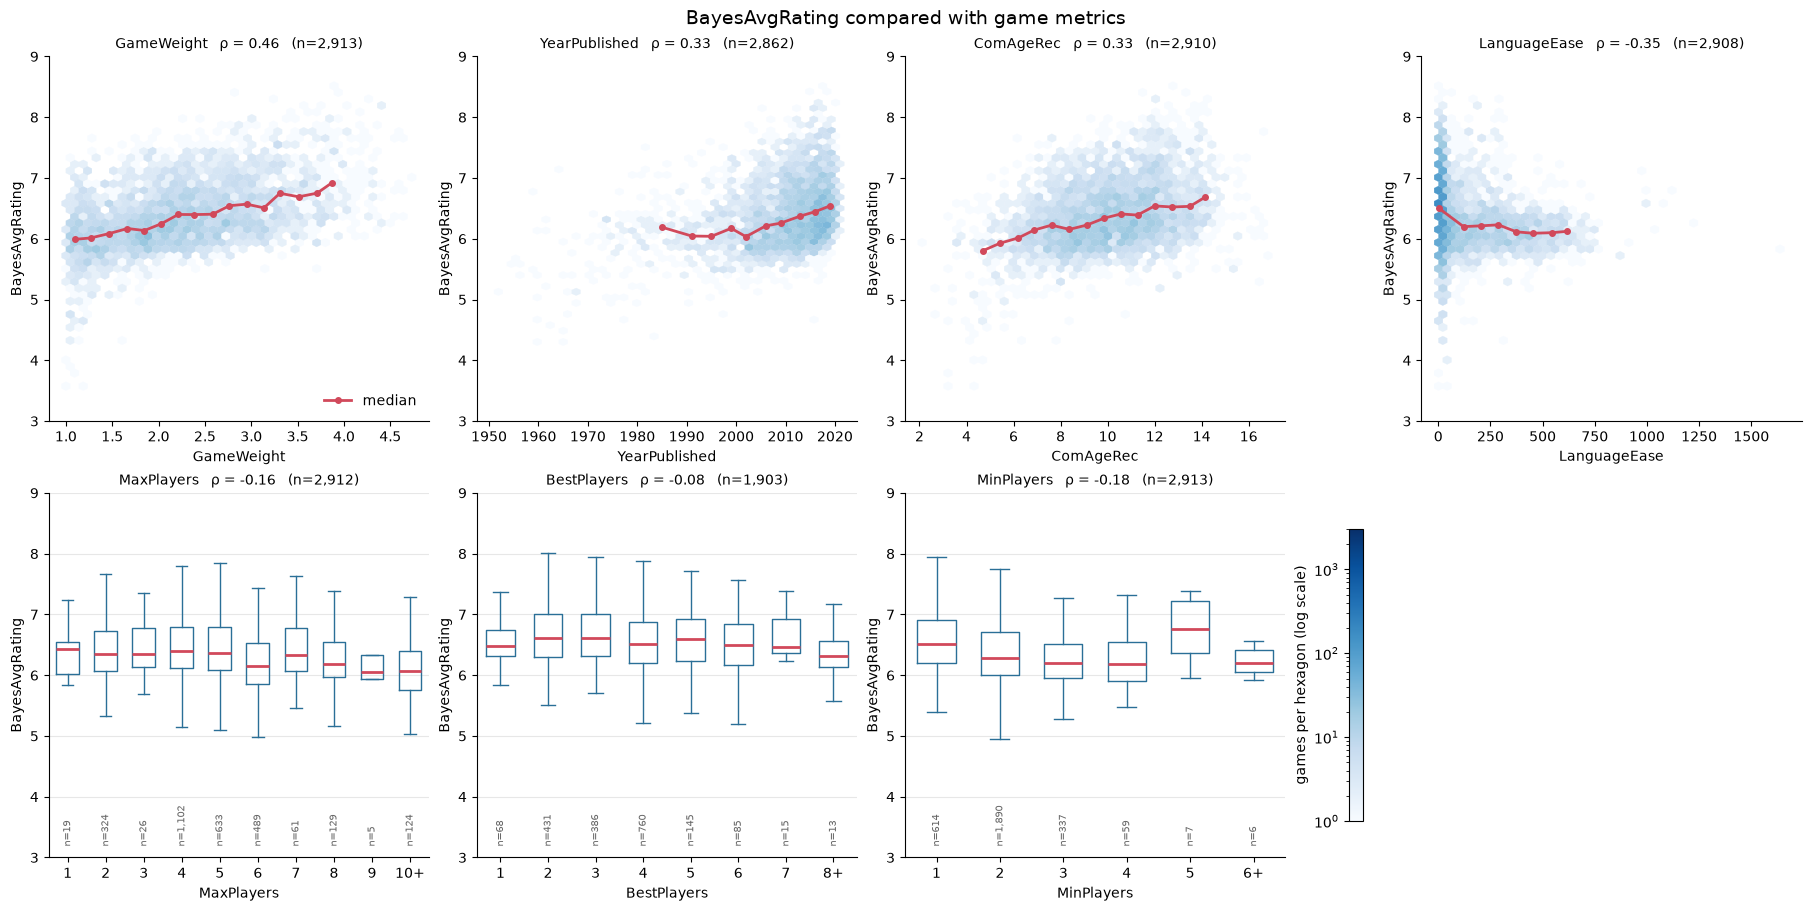

In [8]:
others = num.drop(columns="AvgRating")
corr = others.corrwith(num["AvgRating"], method="spearman").sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(corr.index, corr.values, color=np.where(corr > 0, "#2a6f97", "#c0504d"), height=0.6)
ax.axvline(0, color="#555", lw=0.8)
for y, v in enumerate(corr.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(-1, 1)
ax.set_xlabel("Spearman correlation with AvgRating")
ax.set_title("How strongly each metric moves with average rating")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

plot_against("AvgRating", data=num)
plot_against("BayesAvgRating", data=num)
plot_against("BayesAvgRating", data=num[games["NumUserRatings"] >= 1000])

In [9]:
has_best = gdf["BestPlayers"].ne(0)          # BestPlayers is stored as 0 when missing
order = ["No BestPlayers", "Has BestPlayers"]
colors = {"No BestPlayers": "#9aa5b1", "Has BestPlayers": "#2a6f97"}

cmp = pd.DataFrame({
    "group": has_best.map({True: "Has BestPlayers", False: "No BestPlayers"}),
    "AvgRating": gdf["AvgRating"],
    "NumUserRatings": games["NumUserRatings"],
})

summary = cmp.groupby("group").agg(
    games=("AvgRating", "size"),
    median_rating=("AvgRating", "median"),
    mean_rating=("AvgRating", "mean"),
    median_num_ratings=("NumUserRatings", "median"),
).reindex(order).round(2)
display(summary)

u, p = mannwhitneyu(cmp.loc[has_best, "AvgRating"], cmp.loc[~has_best, "AvgRating"])
print(f"Mann-Whitney U p-value: {p:.2g}")
print(f"Chance a random 'has' game outrates a random 'no' game: {u / (has_best.sum() * (~has_best).sum()):.0%}")

,games,median_rating,mean_rating,median_num_ratings
group,,,,
No BestPlayers,19944,6.37,6.35,104.0
Has BestPlayers,1981,7.16,7.14,3500.0


Mann-Whitney U p-value: 0
Chance a random 'has' game outrates a random 'no' game: 77%


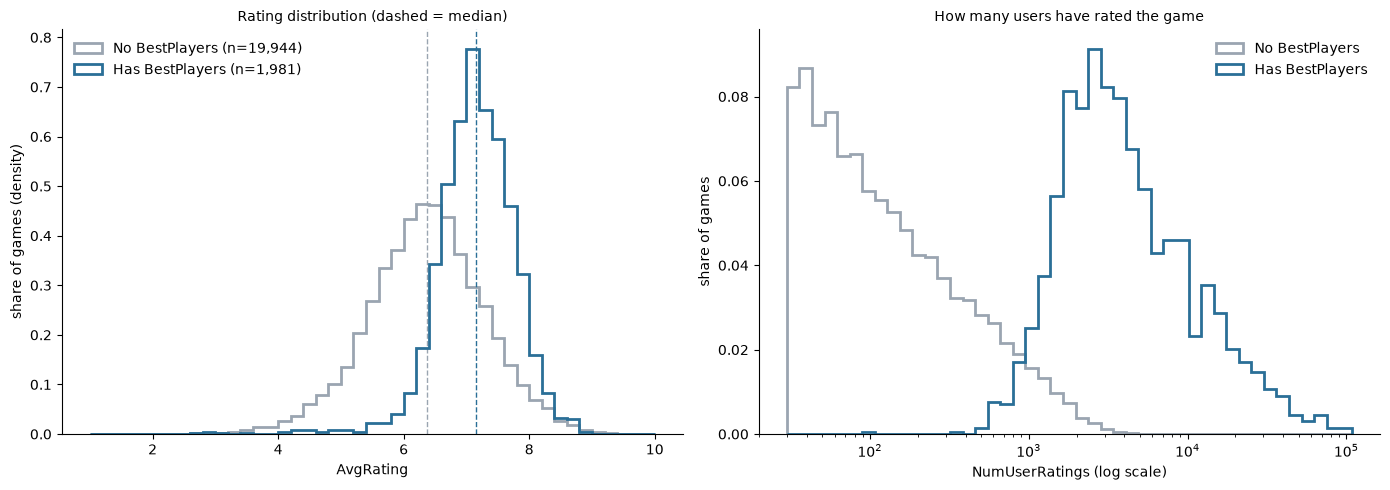

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: rating distributions, normalised so the small group is comparable
bins = np.linspace(1, 10, 46)
for g in order:
    axes[0].hist(cmp.loc[cmp.group == g, "AvgRating"], bins=bins, density=True,
                 histtype="step", lw=2, color=colors[g],
                 label=f"{g} (n={summary.loc[g, 'games']:,.0f})")
    axes[0].axvline(summary.loc[g, "median_rating"], color=colors[g], ls="--", lw=1)
axes[0].set_xlabel("AvgRating")
axes[0].set_ylabel("share of games (density)")
axes[0].set_title("Rating distribution (dashed = median)", fontsize=10)
axes[0].legend(frameon=False)

# Right: how many user ratings each group has
lbins = np.logspace(np.log10(30), np.log10(cmp.NumUserRatings.max()), 46)
for g in order:
    sel = cmp.group == g
    axes[1].hist(cmp.loc[sel, "NumUserRatings"], bins=lbins,
                 weights=np.full(sel.sum(), 1 / sel.sum()),
                 histtype="step", lw=2, color=colors[g], label=g)
axes[1].set_xscale("log")
axes[1].set_xlabel("NumUserRatings (log scale)")
axes[1].set_ylabel("share of games")
axes[1].set_title("How many users have rated the game", fontsize=10)
axes[1].legend(frameon=False)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [11]:
for t in [1000, 2000, 5000]:
    s = cmp[cmp.NumUserRatings >= t]
    h = s.group == "Has BestPlayers"
    print(f"≥{t:>5} ratings: {len(s):>5} games, {h.mean():.0%} have BestPlayers | "
          f"median rating has={s[h].AvgRating.median():.2f}, no={s[~h].AvgRating.median():.2f}")

≥ 1000 ratings:  2913 games, 65% have BestPlayers | median rating has=7.15, no=6.65
≥ 2000 ratings:  1668 games, 90% have BestPlayers | median rating has=7.17, no=6.69
≥ 5000 ratings:   718 games, 99% have BestPlayers | median rating has=7.27, no=6.90


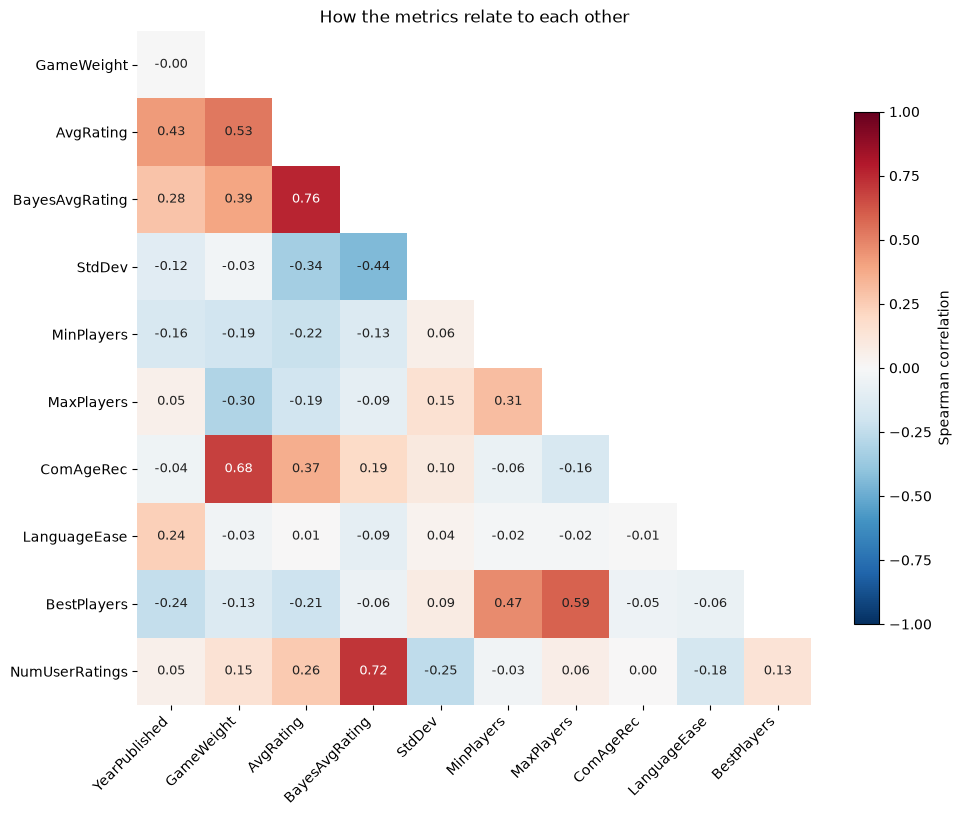

In [12]:
metrics = num.join(games["NumUserRatings"])
corr = metrics.corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))      # hide the duplicate upper half and the diagonal

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.where(~mask), cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(i):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 else "#222")
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
ax.set_xlim(-0.5, len(corr) - 1.5)
ax.set_ylim(len(corr) - 0.5, 0.5)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("How the metrics relate to each other")
plt.tight_layout()
plt.show()

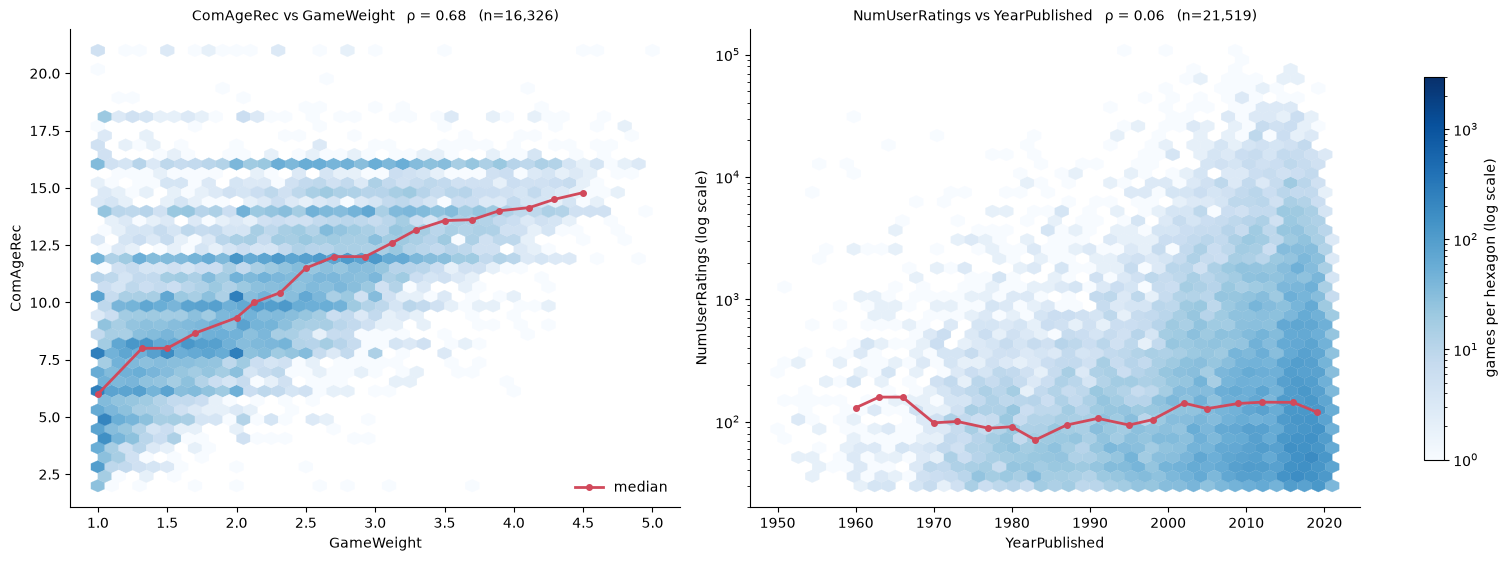

In [13]:
RED = "#d1495b"

def pair_plot(ax, x, y, data=metrics, xlim=None, logy=False):
    d = data[[x, y]].dropna()
    if xlim:
        d = d[d[x].between(*xlim)]
    rho = d[x].corr(d[y], method="spearman")
    hb = ax.hexbin(d[x], d[y], gridsize=40, cmap="Blues", mincnt=1, norm=LogNorm(1, 3000),
                   yscale="log" if logy else "linear", linewidths=0.2)

    # Median line: 20 equal-width bins, skipping bins with < 30 games
    g = d.groupby(pd.cut(d[x], 20), observed=True)
    trend = g.agg(x=(x, "median"), y=(y, "median"), n=(y, "size")).query("n >= 30")
    ax.plot(trend.x, trend.y, color=RED, lw=2, marker="o", ms=4, label="median")

    if logy:
        ax.set_yscale("log")
    ax.set_xlabel(x)
    ax.set_ylabel(y + (" (log scale)" if logy else ""))
    ax.set_title(f"{y} vs {x}   ρ = {rho:.2f}   (n={len(d):,})", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    return hb

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), layout="constrained")
pair_plot(axes[0], "GameWeight", "ComAgeRec")
hb = pair_plot(axes[1], "YearPublished", "NumUserRatings", xlim=(1950, 2021), logy=True)
axes[0].legend(loc="lower right", frameon=False)
fig.colorbar(hb, ax=axes, shrink=0.8, label="games per hexagon (log scale)")
plt.show()